In [10]:
import glob
import os

from matplotlib import font_manager as fm
import matplotlib as mpl

font_dir = os.path.expanduser("~/.local/share/fonts")
for path in glob.glob(os.path.join(font_dir, "lm*.otf")):
    fm.fontManager.addfont(path)
for path in glob.glob(os.path.join(font_dir, "cmu*.otf")):
    fm.fontManager.addfont(path)

mpl.rcParams.update({
    "text.usetex": False,
    "mathtext.fontset": "cm",
    "axes.unicode_minus": False,

    "font.family": "serif",

    "font.serif": ["LMRoman10", "CMU Serif", "DejaVu Serif"],
    "font.sans-serif": ["LMSans10", "CMU Sans Serif", "DejaVu Sans"],
    "font.monospace": ["LMMono10", "CMU Typewriter Text", "DejaVu Sans Mono"],
})


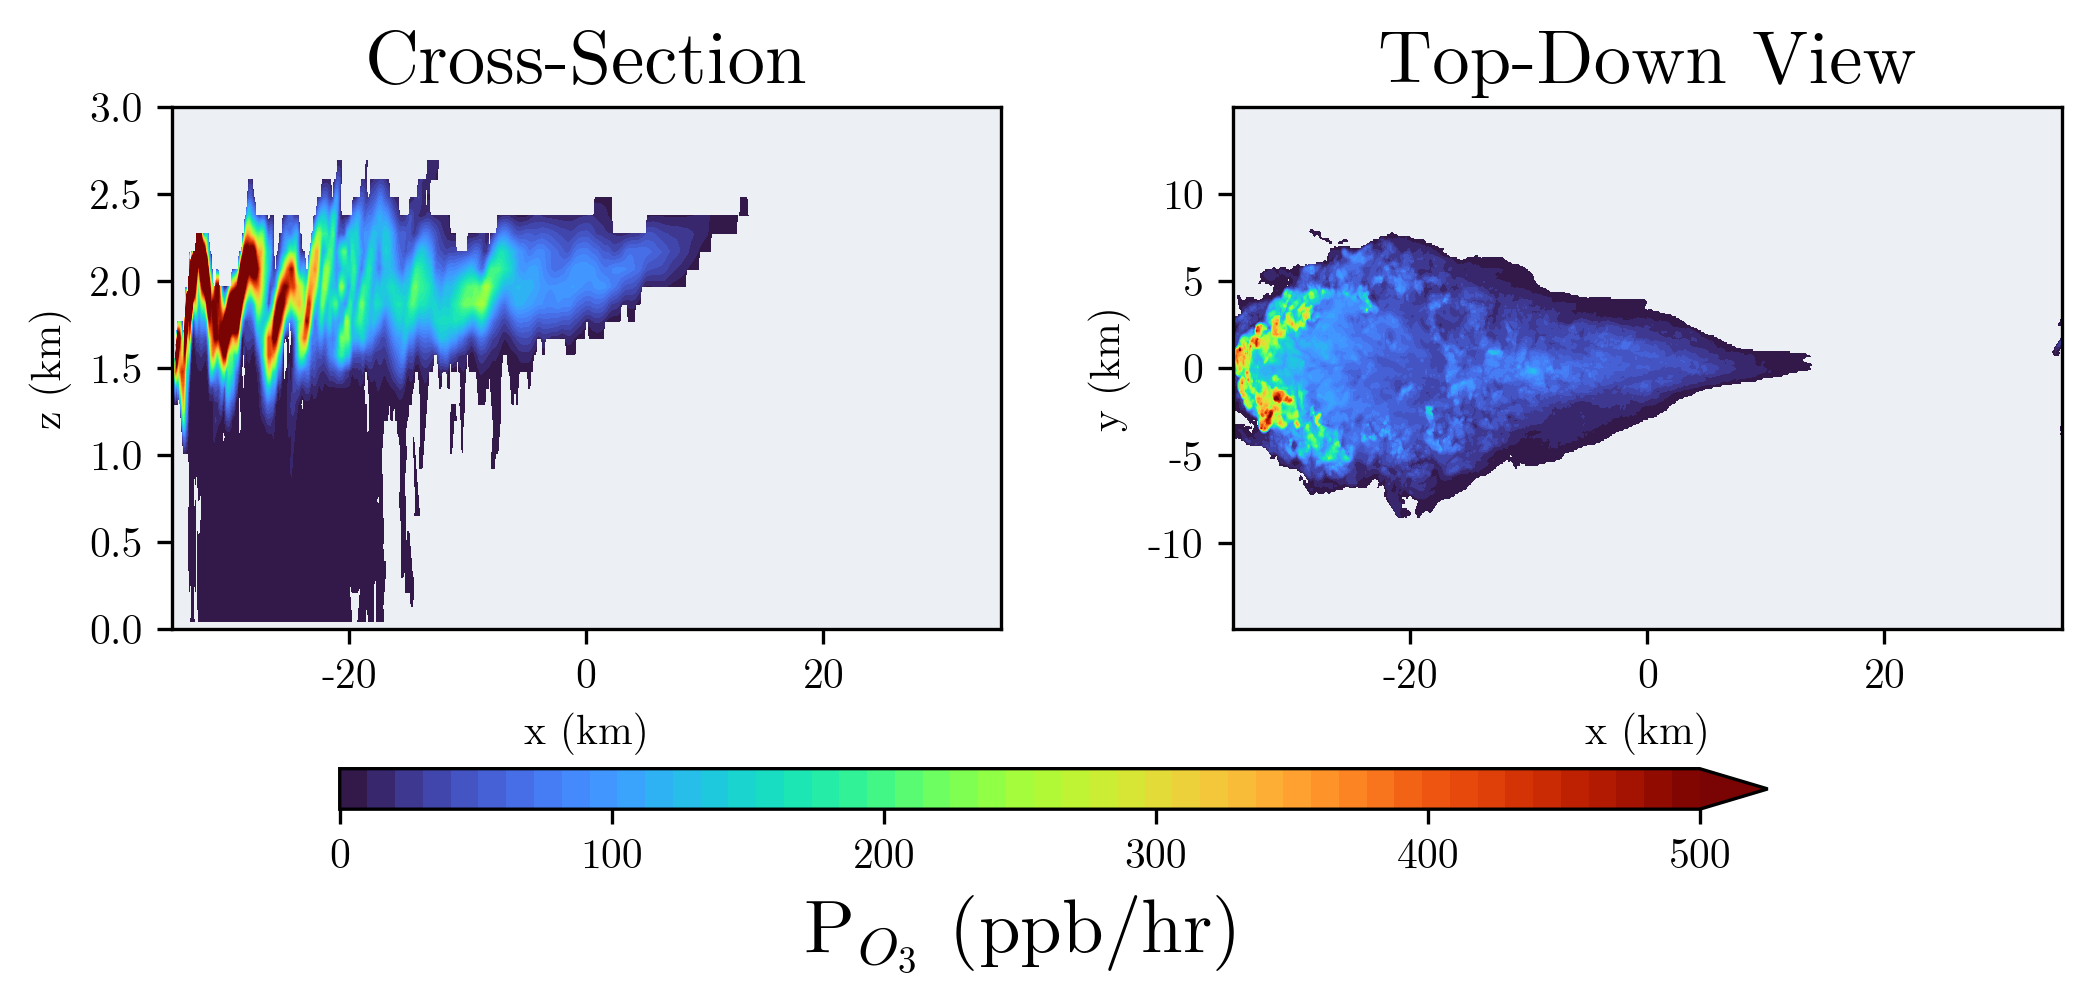

In [ ]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

LES_DATASET = Path("/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/data/les_williams.nc")
ds = xr.open_dataset(LES_DATASET)
if "O3_production_rate_ppbhr" not in ds or "column_pO3" not in ds:
    raise FileNotFoundError("O3_production_rate_ppbhr or column_pO3 missing from " + LES_DATASET.name)

def to_km(values):
    values = np.asarray(values, dtype=float)
    return values / 1000.0 if np.nanmax(np.abs(values)) > 100 else values

x_km = to_km(ds["x"].values if "x" in ds.coords else np.arange(ds.sizes["x"]))
y_km = to_km(ds["y"].values if "y" in ds.coords else np.arange(ds.sizes["y"]))
z_km = to_km(ds["z"].values if "z" in ds.coords else np.arange(ds.sizes["z"]))
y0 = ds.sizes["y"] // 2
section = ds["O3_production_rate_ppbhr"].isel(y=y0)

levels = np.linspace(0, 500, 50)
fig, axes = plt.subplots(1, 2, figsize=(7, 3), dpi=300, sharex=True)
cs = axes[0].contourf(
    x_km, z_km, section, levels=levels, cmap="turbo", extend="max",
)
axes[0].set_ylim(0, 3.0)
axes[0].set_xlabel("x (km)")
axes[0].set_ylabel("z (km)")
axes[0].set_facecolor("#eceff4")
axes[0].set_title("Cross-Section", fontsize=18)
axes[1].contourf(
    x_km, y_km, ds["column_pO3"], levels=levels, cmap="turbo", extend="max",
)
axes[1].set_xlabel("x (km)")
axes[1].set_ylabel("y (km)")
axes[1].set_facecolor("#eceff4")
axes[1].set_title("Top-Down View", fontsize=18)
fig.subplots_adjust(left=0.08, right=0.98, bottom=0.30, top=0.88, wspace=0.28)
cax = fig.add_axes([0.16, 0.10, 0.68, 0.045])
bar = fig.colorbar(cs, cax=cax, orientation="horizontal", extend="max")
bar.set_label(r"P$_{O_3}$ (ppb/hr)", fontsize=18)
bar.set_ticks([0, 100, 200, 300, 400, 500])
png_path = "/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/figs/pngs/figs11.png"
plt.savefig(png_path, dpi=300)
pdf_path = "/home/jpalmo/fs09/Projects/TROPOMI_fire/paper/figs/pdfs/figs11.pdf"
plt.savefig(pdf_path, dpi=300)
plt.show()
